# 02 · Classification: solve predictor

**DMDW topics:** decision trees (entropy ≈ ID3, gini = CART), Naive Bayes, SVM, MLP, Random Forest; accuracy / precision / recall / F1 / confusion matrix; time-based split; preprocessing effects (imputation, scaling).

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display

from cfiq.config import load_config
from cfiq.db import get_engine, read_sql

cfg = load_config()
engine = get_engine()
REPORTS = cfg["paths"]["reports"]
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
from cfiq.mining import classification as C

## Build the (user, problem) dataset from the warehouse

In [2]:
pairs = read_sql(engine, C.PAIRS_SQL)
pairs['contest_start'] = pd.to_datetime(pairs['contest_start'], utc=True)
ratings = read_sql(engine, C.RATINGS_SQL)
ratings['rating_updated_at'] = pd.to_datetime(ratings['rating_updated_at'], utc=True)
problem_cats = read_sql(engine, C.CATEGORIES_SQL)
data, continuous, binary = C.build_features(pairs, problem_cats, ratings, cfg['transform']['default_initial_rating'])
print(len(data), 'pairs, solved share =', round(data['solved'].mean(), 3))
data[['user_key','problem_key','contest_start','solved'] + continuous[:5]].head()

140360 pairs, solved share = 0.494


,user_key,problem_key,contest_start,solved,user_rating,problem_rating,rating_gap,past_rate_match,past_attempts
0,333,4,2010-02-25 17:00:00+00:00,1,1400.0,1500,100.0,0.500000,0.000000
1,333,5,2010-02-25 17:00:00+00:00,1,1400.0,2000,600.0,0.500000,0.000000
2,333,6,2010-02-25 17:00:00+00:00,0,1400.0,2600,1200.0,0.500000,0.000000
3,333,30,2010-04-08 15:45:00+00:00,1,1602.0,1200,-402.0,0.666667,1.386294
4,333,31,2010-04-08 15:45:00+00:00,1,1602.0,1400,-202.0,0.611111,1.386294


## Time-based split (no contest on both sides)

In [3]:
train, test = C.time_split(data, cfg['mining']['classification']['test_fraction'])
print('train', train['contest_start'].min().date(), '..', train['contest_start'].max().date(), len(train))
print('test ', test['contest_start'].min().date(), '..', test['contest_start'].max().date(), len(test))

train 2010-02-25 .. 2026-03-14 112075
test  2026-03-16 .. 2026-11-22 28285


## Train and compare all models (3 preprocessing experiments)

In [4]:
C.run_classification(cfg, engine)
pd.read_csv(REPORTS / 'classification' / 'model_comparison.csv')

,model,accuracy,precision,recall,f1,tn,fp,fn,tp,fit_s
0,Baseline (gap <= 0),0.871133,0.906911,0.824164,0.863560,13105,1184,2461,11535,0.000000
1,"DecisionTree (entropy, ~ID3)",0.884497,0.901986,0.860031,0.880509,12981,1308,1959,12037,1.047784
2,"DecisionTree (gini, CART)",0.886229,0.893300,0.874536,0.883818,12827,1462,1756,12240,0.895032
3,GaussianNB,0.808662,0.869554,0.721563,0.788676,12774,1515,3897,10099,0.050838
4,BernoulliNB,0.847941,0.854272,0.835167,0.844611,12295,1994,2307,11689,0.042474
5,SVM (RBF kernel),0.889588,0.883041,0.895470,0.889212,12629,1660,1463,12533,0.712249
6,MLP neural network,0.890437,0.889652,0.888825,0.889238,12746,1543,1556,12440,5.356145
7,RandomForest,0.890896,0.892164,0.886682,0.889414,12789,1500,1586,12410,5.375658


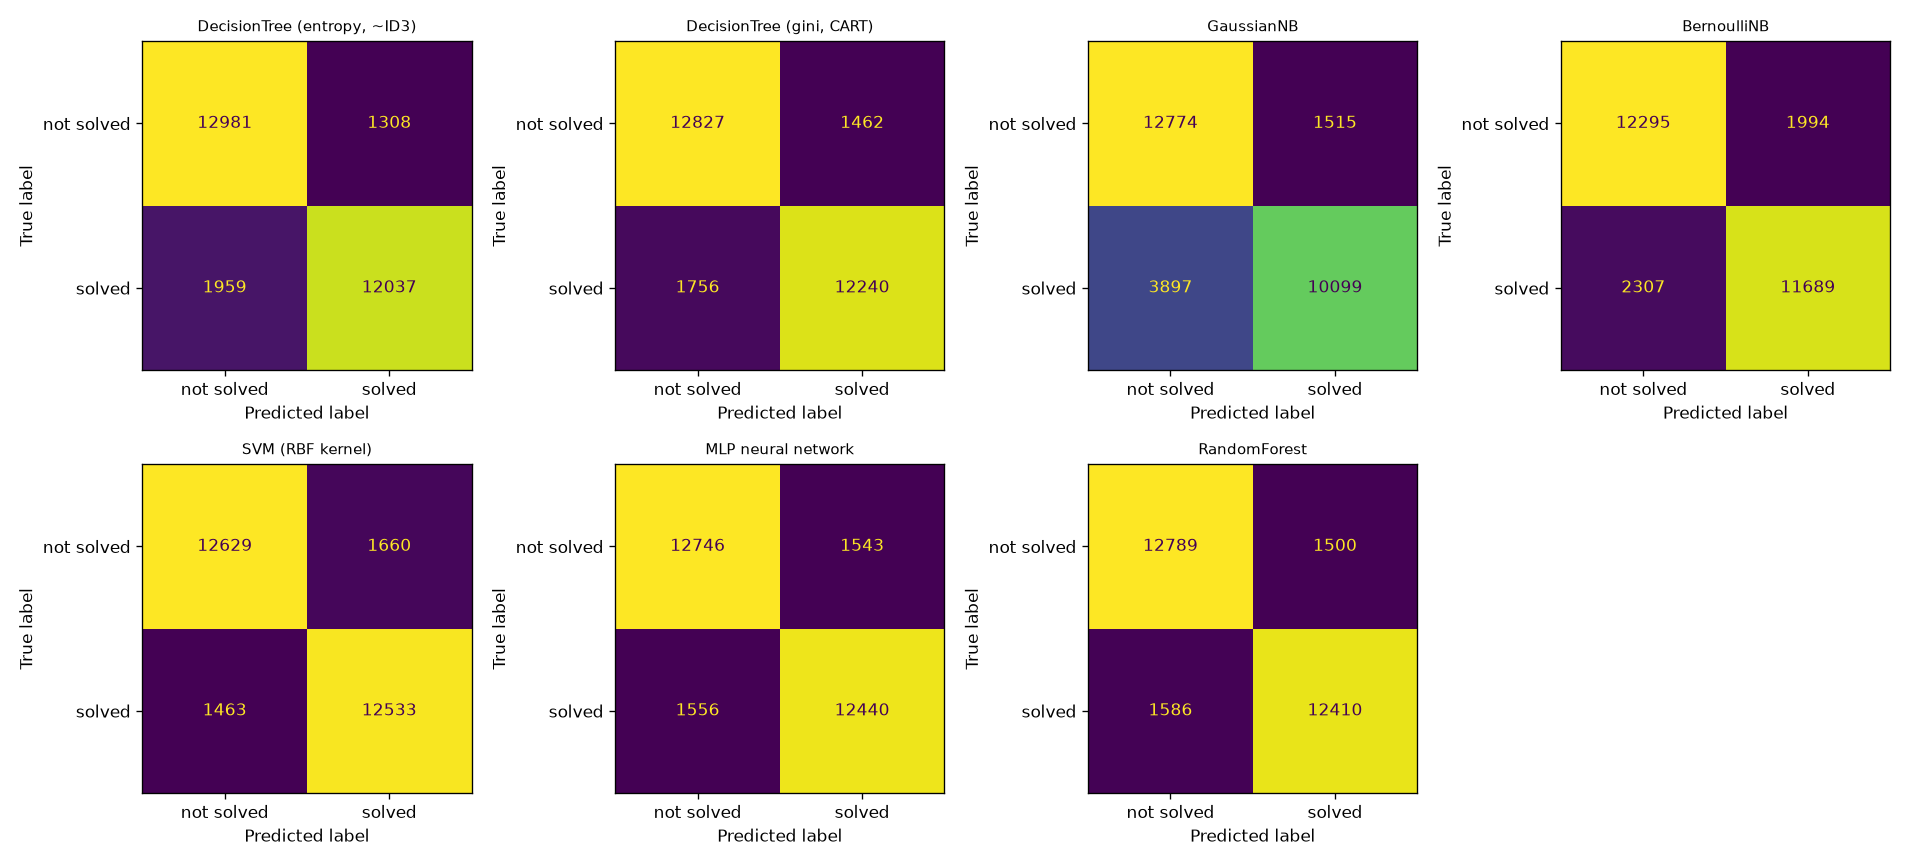

In [5]:
Image(REPORTS / 'classification' / 'confusion_matrices.png')

## Missing-value strategy and scaling

In [6]:
m = pd.read_csv(REPORTS / 'classification' / 'all_metrics.csv')
m.pivot(index='model', columns='experiment', values='f1').round(3)

experiment,drop+zscore,impute+minmax,impute+zscore
model,,,
Baseline (gap <= 0),0.876,0.864,0.864
BernoulliNB,0.858,0.838,0.845
"DecisionTree (entropy, ~ID3)",0.892,0.881,0.881
"DecisionTree (gini, CART)",0.895,0.884,0.884
GaussianNB,0.799,0.789,0.789
MLP neural network,0.900,0.890,0.889
RandomForest,0.899,0.889,0.889
SVM (RBF kernel),0.898,0.884,0.889


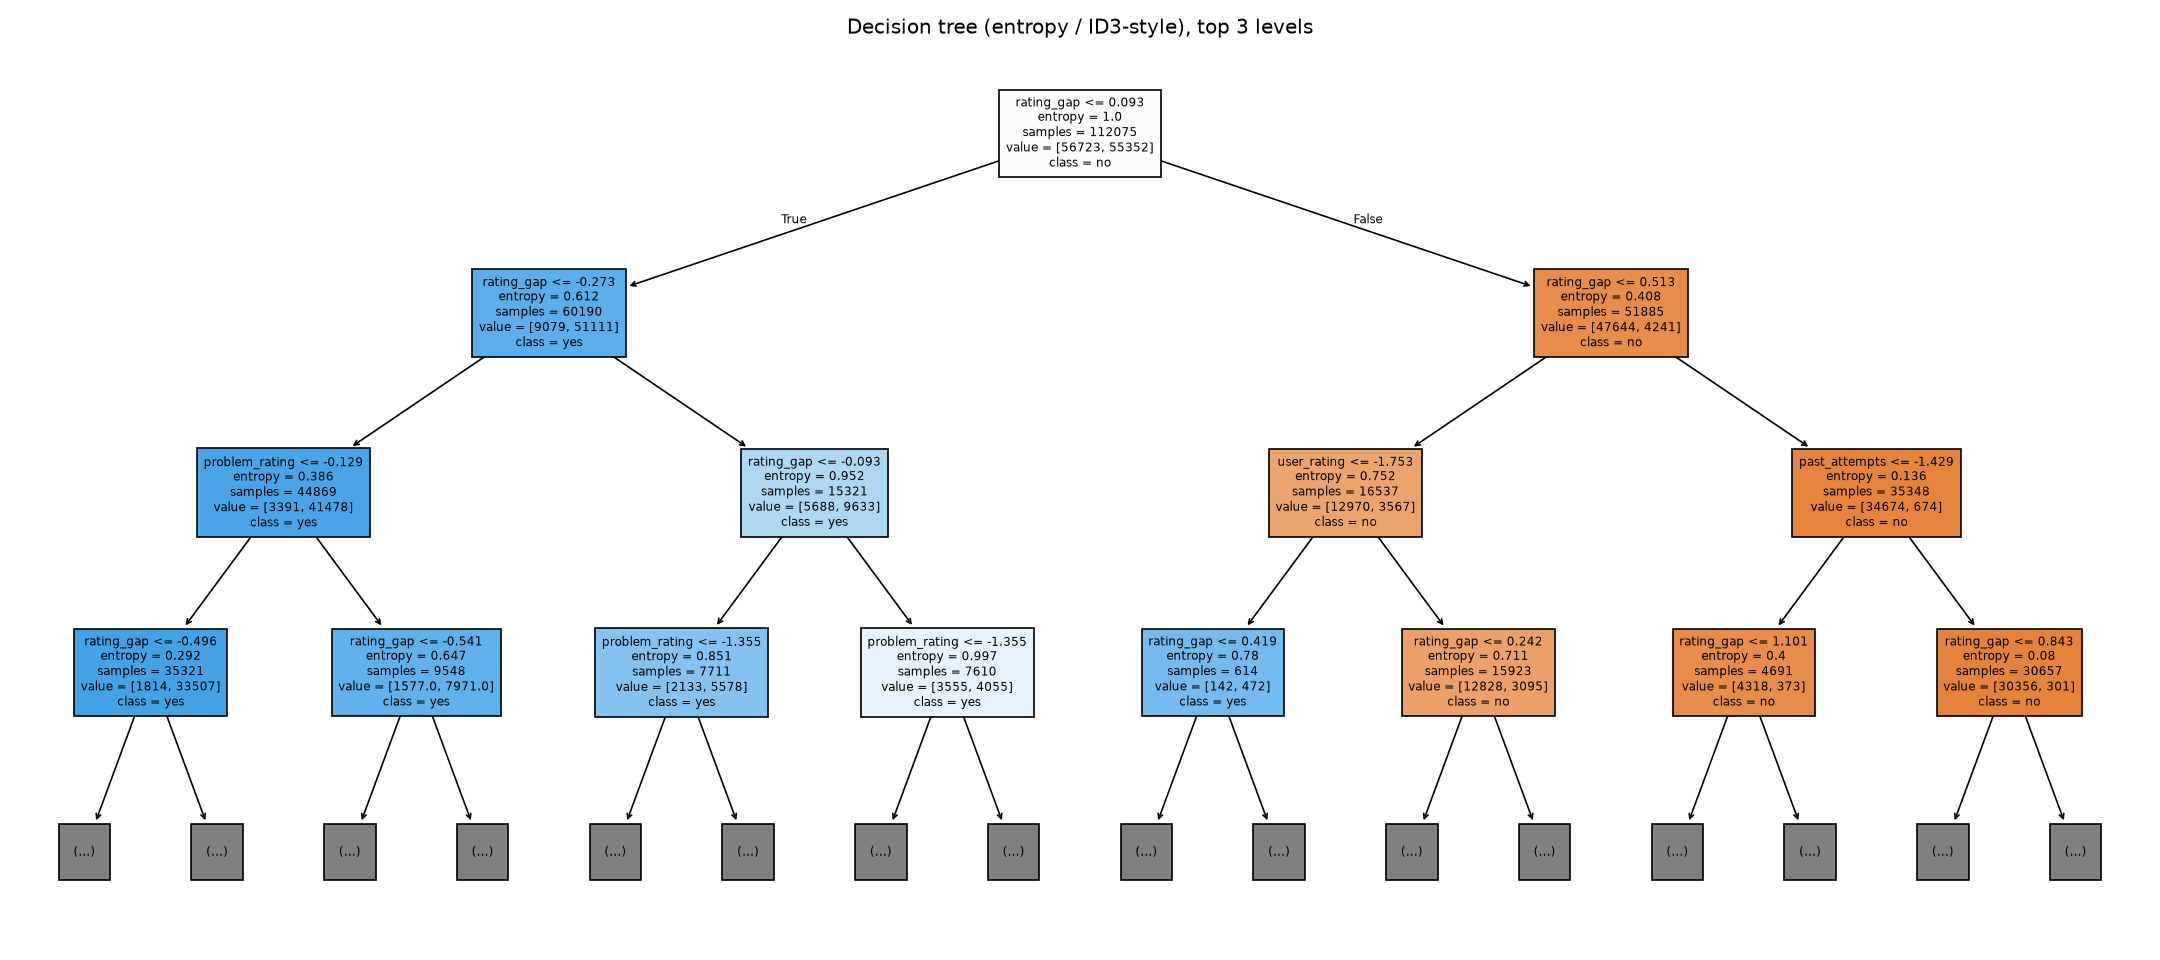

In [7]:
Image(REPORTS / 'classification' / 'decision_tree_entropy.png')

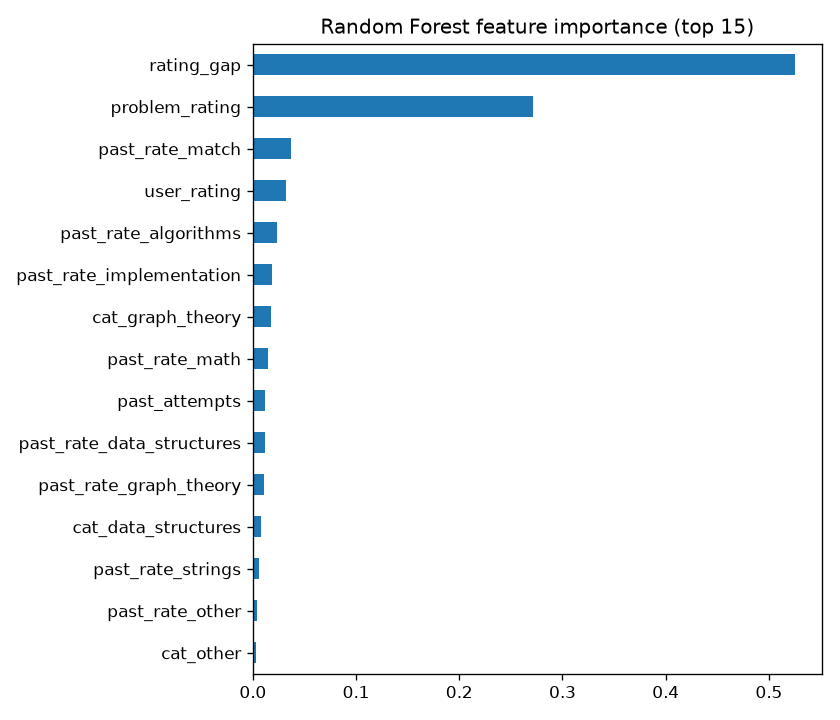

In [8]:
Image(REPORTS / 'classification' / 'rf_feature_importance.png')